# TinyML en ESP32 – Pronóstico de temperatura y humedad en la bodega de café

**Objetivo:** entrenar un modelo con las lecturas reales del DHT11 de la bodega (`lecturas_bodega.csv`) que, a partir de los **últimos 4 minutos** de lecturas, prediga la **temperatura y la humedad dentro de 5 minutos**. El modelo se convierte a TensorFlow Lite y se ejecuta en el ESP32 con la librería **EloquentTinyML**, igual que el ejemplo de la función seno visto en clase.

Con la predicción, el ESP32 aplica la misma regla de la bodega (T entre 15 y 25 °C, HR entre 50 y 65 %) para generar una **alerta anticipada**: avisa que la bodega va a salir de rango antes de que ocurra.

Flujo:
1. Cargar y explorar los datos.
2. Justificar qué modelo tiene sentido con estos datos.
3. Construir el dataset (ventanas), dividir en entrenamiento / validación / prueba.
4. Entrenar el Modelo 1 (regresión lineal) y el Modelo 2 (red densa 16-16).
5. Evaluar contra una línea base y elegir el mejor.
6. Convertir a TFLite cuantizado y exportar el `.h` para Arduino.

## 1. Librerías y semillas

In [2]:
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

SEED = 1337
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)          # mismos pesos iniciales en cada ejecución
tf.config.experimental.enable_op_determinism()
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Cargar los datos
En Colab, si el archivo no está en `/content`, la celda abre el diálogo para subirlo.

In [3]:
CSV_PATH = "lecturas_bodega.csv"

if not os.path.exists(CSV_PATH):
    from google.colab import files
    subido = files.upload()                 # seleccionar el CSV
    CSV_PATH = list(subido.keys())[0]

df = pd.read_csv(CSV_PATH, parse_dates=["fecha"])
df = df.sort_values("fecha").reset_index(drop=True)
print(df.shape)
df.head()

Saving lecturas_bodega (3).csv to lecturas_bodega (3).csv
(2933, 6)


,fecha,dispositivo,temperatura,humedad,estado,led
0,2026-11-01 14:25:04,bodega-esp32,23.5,41.7,ALERTA,OFF
1,2026-11-01 14:25:14,bodega-esp32,23.5,41.9,ALERTA,OFF
2,2026-11-01 14:25:24,bodega-esp32,23.5,42.0,ALERTA,OFF
3,2026-11-01 14:25:34,bodega-esp32,23.4,42.1,ALERTA,OFF
4,2026-11-01 14:25:44,bodega-esp32,23.4,42.5,ALERTA,OFF


In [4]:
df[["temperatura", "humedad"]].describe()

,temperatura,humedad
count,2933.000000,2933.000000
mean,22.997511,51.060518
std,1.025722,9.017991
min,20.500000,39.000000
25%,22.500000,42.600000
50%,23.000000,47.800000
75%,23.400000,59.700000
max,26.300000,69.800000


## 3. Exploración: ¿qué modelo tiene sentido?

Se evaluaron tres ideas antes de decidir:

* **Temperatura en función de la humedad (o al revés).** Depende de qué tan correlacionadas estén.
* **Temperatura/humedad en función de la hora.** Depende de cuántas horas del día cubren los datos.
* **Clasificar `estado` (OK / ALERTA).** El estado lo calcula el propio ESP32 con una regla fija, así que un modelo solo aprendería un `if`.

In [5]:
# Las lecturas llegan cada 10 s; un salto > 60 s indica que el ESP32 estuvo apagado -> nueva sesión
df["sesion"] = (df["fecha"].diff().dt.total_seconds() > 60).cumsum()
print(df.groupby("sesion").agg(inicio=("fecha", "min"), fin=("fecha", "max"), lecturas=("fecha", "size")))
print("\nPaso típico entre lecturas (s):", df["fecha"].diff().dt.total_seconds().median())

                    inicio                 fin  lecturas
sesion                                                  
0      2026-11-01 14:25:04 2026-11-01 15:25:44       365
1      2026-11-05 21:44:10 2026-11-05 22:28:30       267
2      2026-11-06 18:31:18 2026-11-06 21:59:07      1248
3      2026-11-07 07:32:51 2026-11-07 10:28:31      1053

Paso típico entre lecturas (s): 10.0


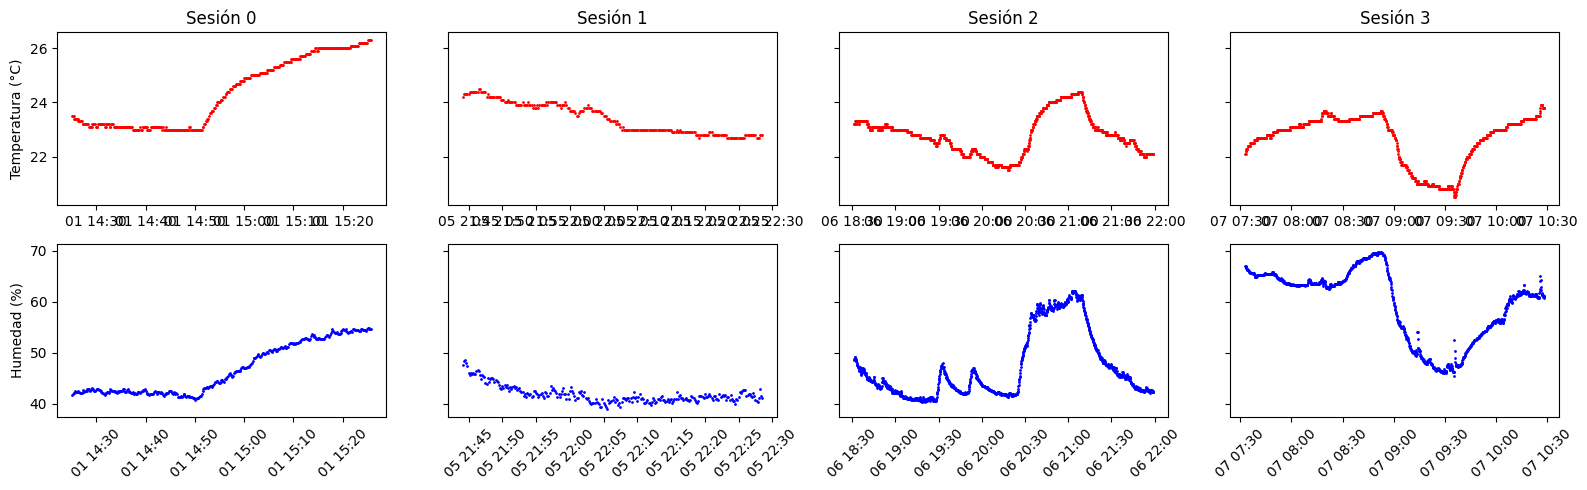

In [6]:
fig, axs = plt.subplots(2, df["sesion"].nunique(), figsize=(16, 5), sharey="row")
for j, (s, g) in enumerate(df.groupby("sesion")):
    axs[0, j].plot(g["fecha"], g["temperatura"], "r.", ms=2); axs[0, j].set_title(f"Sesión {s}")
    axs[1, j].plot(g["fecha"], g["humedad"], "b.", ms=2)
    axs[1, j].tick_params(axis="x", rotation=45)
axs[0, 0].set_ylabel("Temperatura (°C)"); axs[1, 0].set_ylabel("Humedad (%)")
plt.tight_layout(); plt.show()

Correlación temperatura-humedad: r = 0.29  ->  R² máximo de una regresión lineal ≈ 0.08


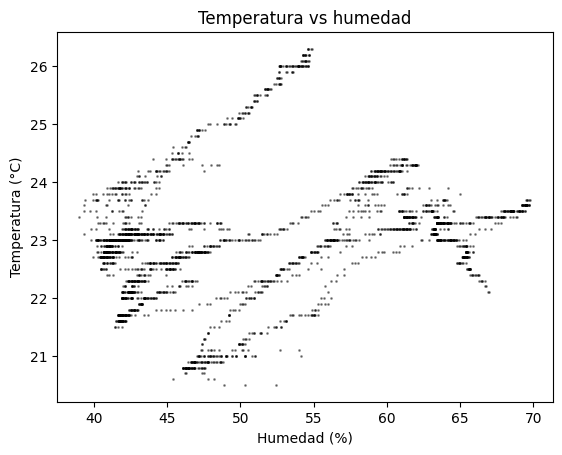

Horas con datos: [7, 8, 9, 10, 14, 15, 18, 19, 20, 21, 22]
Coincidencia de 'estado' con la regla 15-25 °C / 50-65 %: 1.0


In [7]:
# Idea 1: ¿se puede predecir una variable a partir de la otra?
r = df["temperatura"].corr(df["humedad"])
print(f"Correlación temperatura-humedad: r = {r:.2f}  ->  R² máximo de una regresión lineal ≈ {r**2:.2f}")

plt.plot(df["humedad"], df["temperatura"], "k.", ms=2, alpha=0.4)
plt.xlabel("Humedad (%)"); plt.ylabel("Temperatura (°C)"); plt.title("Temperatura vs humedad")
plt.show()

# Idea 2: ¿qué horas del día están cubiertas?
print("Horas con datos:", sorted(int(h) for h in df["fecha"].dt.hour.unique()))

# Idea 3: ¿el estado es una regla fija?
regla = np.where(df["temperatura"].between(15, 25) & df["humedad"].between(50, 65), "OK", "ALERTA")
print("Coincidencia de 'estado' con la regla 15-25 °C / 50-65 %:", (regla == df["estado"]).mean())

**Conclusión de la exploración**

* La correlación T–H es baja (r ≈ 0,29, R² ≈ 0,08): una regresión de una variable contra la otra explicaría menos del 10 % de la variación. No sirve.
* Solo hay 4 sesiones y 11 horas distintas del día. Un modelo "en función de la hora" estaría memorizando qué pasó esas tardes concretas y no generalizaría a horas sin datos.
* `estado` coincide al 100 % con la regla del ESP32: un clasificador no aporta nada.

Lo que sí tienen estos datos es **continuidad temporal** (una lectura cada 10 s durante ~8 horas). Por eso el modelo elegido es de **series de tiempo**: con lo que pasó en los últimos minutos, predecir el valor futuro. Además es útil para la bodega: si la humedad va subiendo, el ESP32 avisa antes de que salga de rango.

## 4. Construcción del dataset (ventanas)

Para cada instante *t* de cada sesión:

* **Entradas (8):** cuánto cambió cada variable respecto al valor actual hace 1, 2, 3 y 4 minutos
  `[T(t-1min)-T(t), …, T(t-4min)-T(t), H(t-1min)-H(t), …, H(t-4min)-H(t)]`
* **Salidas (2):** cuánto va a cambiar cada variable en 5 minutos: `[T(t+5min)-T(t), H(t+5min)-H(t)]`

En el ESP32: `T_predicha = T_actual + ΔT_predicho`.

Se trabaja con **diferencias** y no con valores absolutos porque con solo 8 horas de datos el modelo no ha visto todos los niveles posibles de T y H; las diferencias describen la *tendencia*, que sí se repite entre sesiones. Las ventanas nunca cruzan de una sesión a otra.

In [8]:
PASO_S     = 10                      # segundos entre lecturas
LAGS_MIN   = [1, 2, 3, 4]            # minutos hacia atrás
PASO_LAG   = 60 // PASO_S            # 6 lecturas = 1 minuto
HORIZONTE  = 5 * 60 // PASO_S        # 30 lecturas = 5 minutos
HIST       = max(LAGS_MIN) * PASO_LAG   # 24 lecturas hacia atrás

def construir_ventanas(df):
    X, Y, actual, sesion, fecha = [], [], [], [], []
    for s, g in df.groupby("sesion"):
        T = g["temperatura"].values; H = g["humedad"].values; F = g["fecha"].values
        for i in range(HIST, len(g) - HORIZONTE):
            dT = [T[i - k*PASO_LAG] - T[i] for k in LAGS_MIN]
            dH = [H[i - k*PASO_LAG] - H[i] for k in LAGS_MIN]
            X.append(dT + dH)
            Y.append([T[i + HORIZONTE] - T[i], H[i + HORIZONTE] - H[i]])
            actual.append([T[i], H[i]]); sesion.append(s); fecha.append(F[i])
    return (np.array(X, np.float32), np.array(Y, np.float32),
            np.array(actual, np.float32), np.array(sesion), np.array(fecha))

X, Y, ACT, SES, FECHA = construir_ventanas(df)
print("X:", X.shape, " Y:", Y.shape)

X: (2717, 8)  Y: (2717, 2)


### División entrenamiento / validación / prueba (60 / 20 / 20)

En el ejemplo del seno se mezclaban los datos al azar. Aquí **no se puede**: dos ventanas seguidas (separadas 10 s) son casi idénticas, así que mezclar pondría en prueba datos prácticamente vistos en entrenamiento y el error saldría artificialmente bajo. Se divide **en orden cronológico dentro de cada sesión**: el primer 60 % entrena, el siguiente 20 % valida y el último 20 % se usa como prueba.

In [9]:
idx_tr, idx_va, idx_te = [], [], []
for s in np.unique(SES):
    ii = np.where(SES == s)[0]
    a, b = int(0.6 * len(ii)), int(0.8 * len(ii))
    idx_tr += list(ii[:a]); idx_va += list(ii[a:b]); idx_te += list(ii[b:])
idx_tr, idx_va, idx_te = map(np.array, (idx_tr, idx_va, idx_te))

x_train, y_train = X[idx_tr], Y[idx_tr]
x_validate, y_validate = X[idx_va], Y[idx_va]
x_test, y_test = X[idx_te], Y[idx_te]
assert len(x_train) + len(x_validate) + len(x_test) == len(X)
print(len(x_train), len(x_validate), len(x_test))

1628 544 545


### Normalización
Se calcula media y desviación **solo con entrenamiento**. Estas mismas constantes se exportan al ESP32.

In [10]:
X_MEAN, X_STD = x_train.mean(0), x_train.std(0) + 1e-6
Y_MEAN, Y_STD = y_train.mean(0), y_train.std(0) + 1e-6

norm_x   = lambda x: (x - X_MEAN) / X_STD
norm_y   = lambda y: (y - Y_MEAN) / Y_STD
desnorm_y = lambda y: y * Y_STD + Y_MEAN

xn_train, xn_val, xn_test = norm_x(x_train), norm_x(x_validate), norm_x(x_test)
yn_train, yn_val = norm_y(y_train), norm_y(y_validate)

## 5. Línea base: persistencia

Antes de entrenar hay que saber contra qué compararse. La predicción más simple es **"en 5 minutos todo seguirá igual"** (ΔT = ΔH = 0). Si un modelo no supera esto, no sirve.

In [11]:
def mae(pred, real):
    return np.abs(pred - real).mean(0)

mae_pers = mae(np.zeros_like(y_test), y_test)
print(f"Persistencia -> MAE temperatura: {mae_pers[0]:.3f} °C | MAE humedad: {mae_pers[1]:.3f} %")

Persistencia -> MAE temperatura: 0.151 °C | MAE humedad: 1.227 %


## 6. Modelo 1: regresión lineal

Una regresión lineal en Keras es una sola capa `Dense` sin función de activación: `salida = W·x + b`. Así se mantiene el mismo flujo de conversión a TFLite que en clase.

In [12]:
N_ENTRADAS, N_SALIDAS = X.shape[1], Y.shape[1]

model_1 = tf.keras.Sequential([
    keras.Input(shape=(N_ENTRADAS,)),
    layers.Dense(N_SALIDAS)              # sin activación = regresión lineal
])
model_1.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.01), loss="mse", metrics=["mae"])
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18 (72.00 B)

 Trainable params: 18 (72.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, restore_best_weights=True)   # usada por el Modelo 2
parada_1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)

# Lotes de 64 + tasa de aprendizaje 0.01: el modelo lineal llega al mismo resultado mucho más rápido
history_1 = model_1.fit(xn_train, yn_train, epochs=1500, batch_size=64,
                        validation_data=(xn_val, yn_val), callbacks=[parada_1], verbose=0)
print("Épocas entrenadas:", len(history_1.history["loss"]))

## 7. Modelo 2: red densa (16-16), como el modelo_2 del ejemplo

Se agrega una capa intermedia para ver si una relación no lineal mejora el pronóstico.

In [ ]:
model_2 = tf.keras.Sequential([
    keras.Input(shape=(N_ENTRADAS,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(N_SALIDAS)
])
model_2.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
model_2.summary()

history_2 = model_2.fit(xn_train, yn_train, epochs=500, batch_size=16,
                        validation_data=(xn_val, yn_val), callbacks=[parada], verbose=0)
print("Épocas entrenadas:", len(history_2.history["loss"]))

## 8. Curvas de entrenamiento

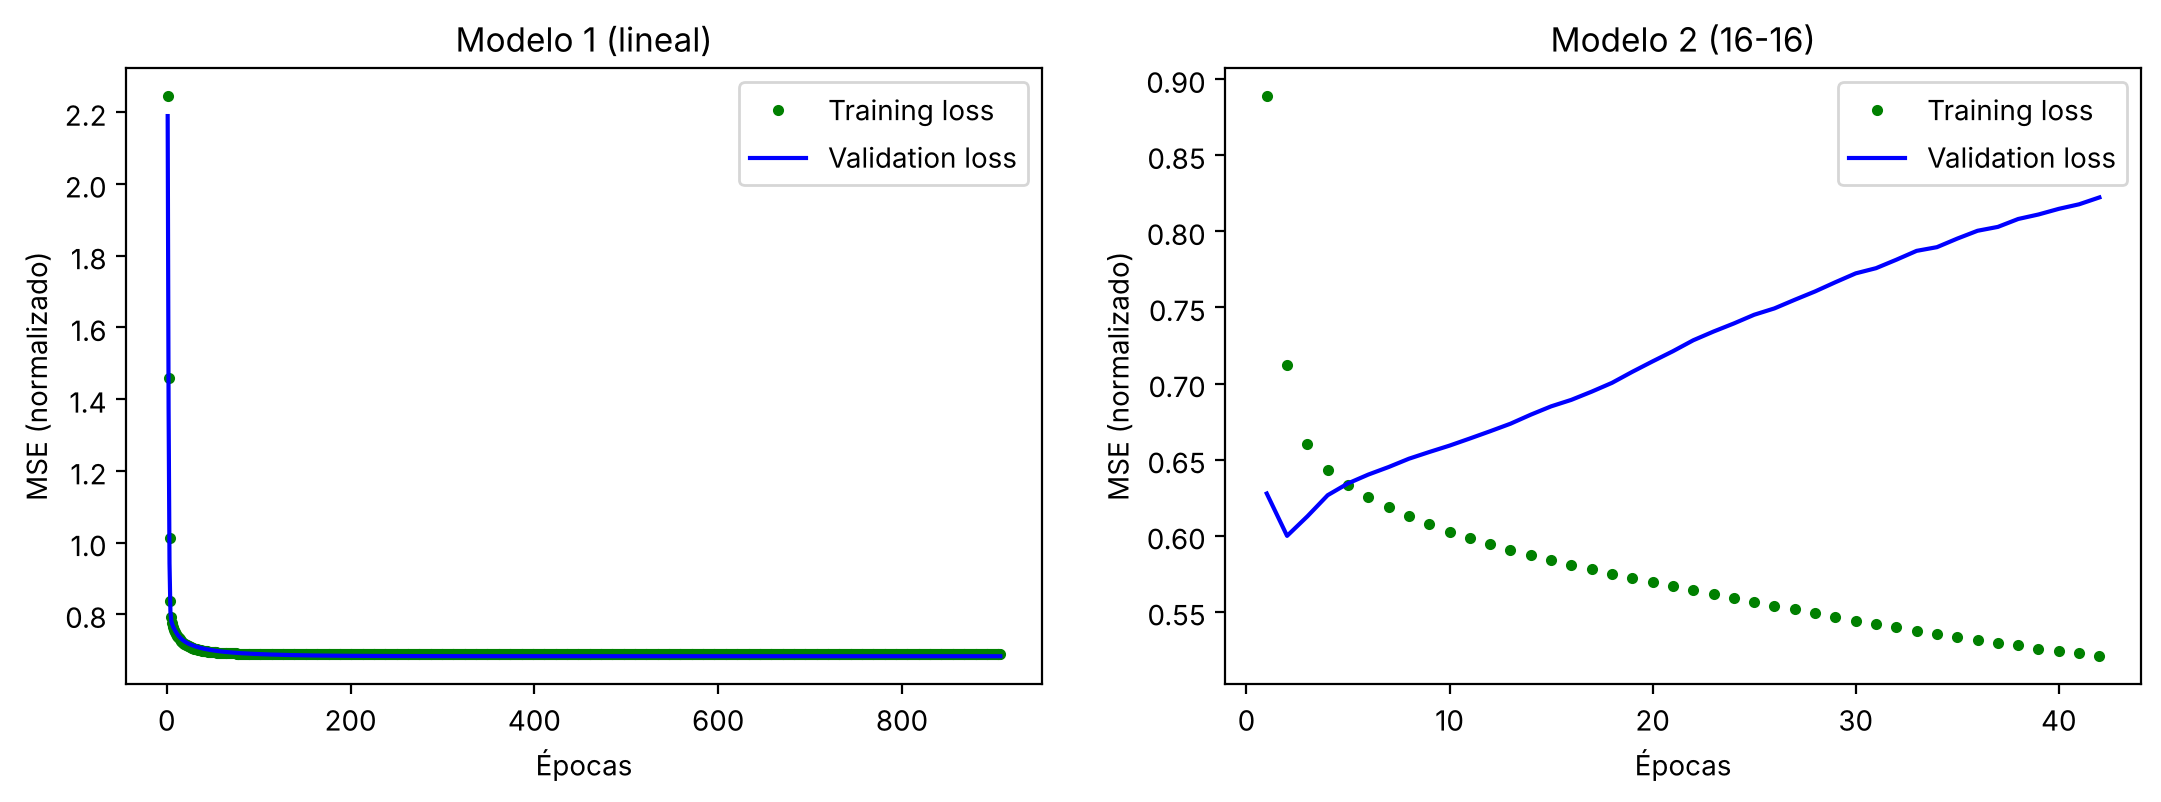

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, h, nombre in [(axs[0], history_1, "Modelo 1 (lineal)"), (axs[1], history_2, "Modelo 2 (16-16)")]:
    ep = range(1, len(h.history["loss"]) + 1)
    ax.plot(ep, h.history["loss"], "g.", label="Training loss")
    ax.plot(ep, h.history["val_loss"], "b", label="Validation loss")
    ax.set_title(nombre); ax.set_xlabel("Épocas"); ax.set_ylabel("MSE (normalizado)"); ax.legend()
plt.show()

## 9. Evaluación en prueba (en °C y %)

In [ ]:
pred_1 = desnorm_y(model_1.predict(xn_test, verbose=0))
pred_2 = desnorm_y(model_2.predict(xn_test, verbose=0))

tabla = pd.DataFrame({
    "MAE temperatura (°C)": [mae_pers[0], mae(pred_1, y_test)[0], mae(pred_2, y_test)[0]],
    "MAE humedad (%)":      [mae_pers[1], mae(pred_1, y_test)[1], mae(pred_2, y_test)[1]],
}, index=["Persistencia", "Modelo 1 (lineal)", "Modelo 2 (16-16)"])
tabla["Mejora humedad vs persistencia"] = (1 - tabla["MAE humedad (%)"] / mae_pers[1]).map("{:.0%}".format)
tabla.round(3)

E0000 00:00:1794274119.608509   15202 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,MAE temperatura (°C),MAE humedad (%),Mejora humedad vs persistencia
Persistencia,0.151,1.227,0%
Modelo 1 (lineal),0.139,0.882,28%
Modelo 2 (16-16),0.137,0.875,29%


### Elección del modelo a exportar

Se comparan los dos modelos con el error absoluto medio (MAE) en el conjunto de **validación**, sumando el error de temperatura y el de humedad. No se usa el conjunto de prueba para elegir, porque ese se reserva para reportar el desempeño final; si se usara para decidir, su resultado dejaría de ser una medida imparcial.

Regla de decisión: se exporta la red 16-16 solo si su error es al menos un **2 % menor** que el del modelo lineal (`val_2 < 0.98 * val_1`). Si la mejora es menor, se prefiere el modelo lineal, porque es más simple (18 parámetros frente a 450) y, con tan pocos datos, tiene menos riesgo de sobreajuste.

In [ ]:
# Elección del modelo con el error de VALIDACIÓN (el de prueba solo se usa para reportar).
# Si la red no mejora al menos un 2 % al modelo lineal, se prefiere el lineal (más simple, menos riesgo de sobreajuste).
val_1 = mae(desnorm_y(model_1.predict(xn_val, verbose=0)), y_validate).sum()
val_2 = mae(desnorm_y(model_2.predict(xn_val, verbose=0)), y_validate).sum()
modelo_final, nombre_final = (model_2, "Modelo 2 (16-16)") if val_2 < 0.98 * val_1 else (model_1, "Modelo 1 (lineal)")
pred_final = pred_1 if modelo_final is model_1 else pred_2
print(f"MAE validación (T+H): lineal={val_1:.3f}  16-16={val_2:.3f}  ->  se exporta: {nombre_final}")

MAE validación (T+H): lineal=1.489  16-16=1.363  ->  se exporta: Modelo 2 (16-16)


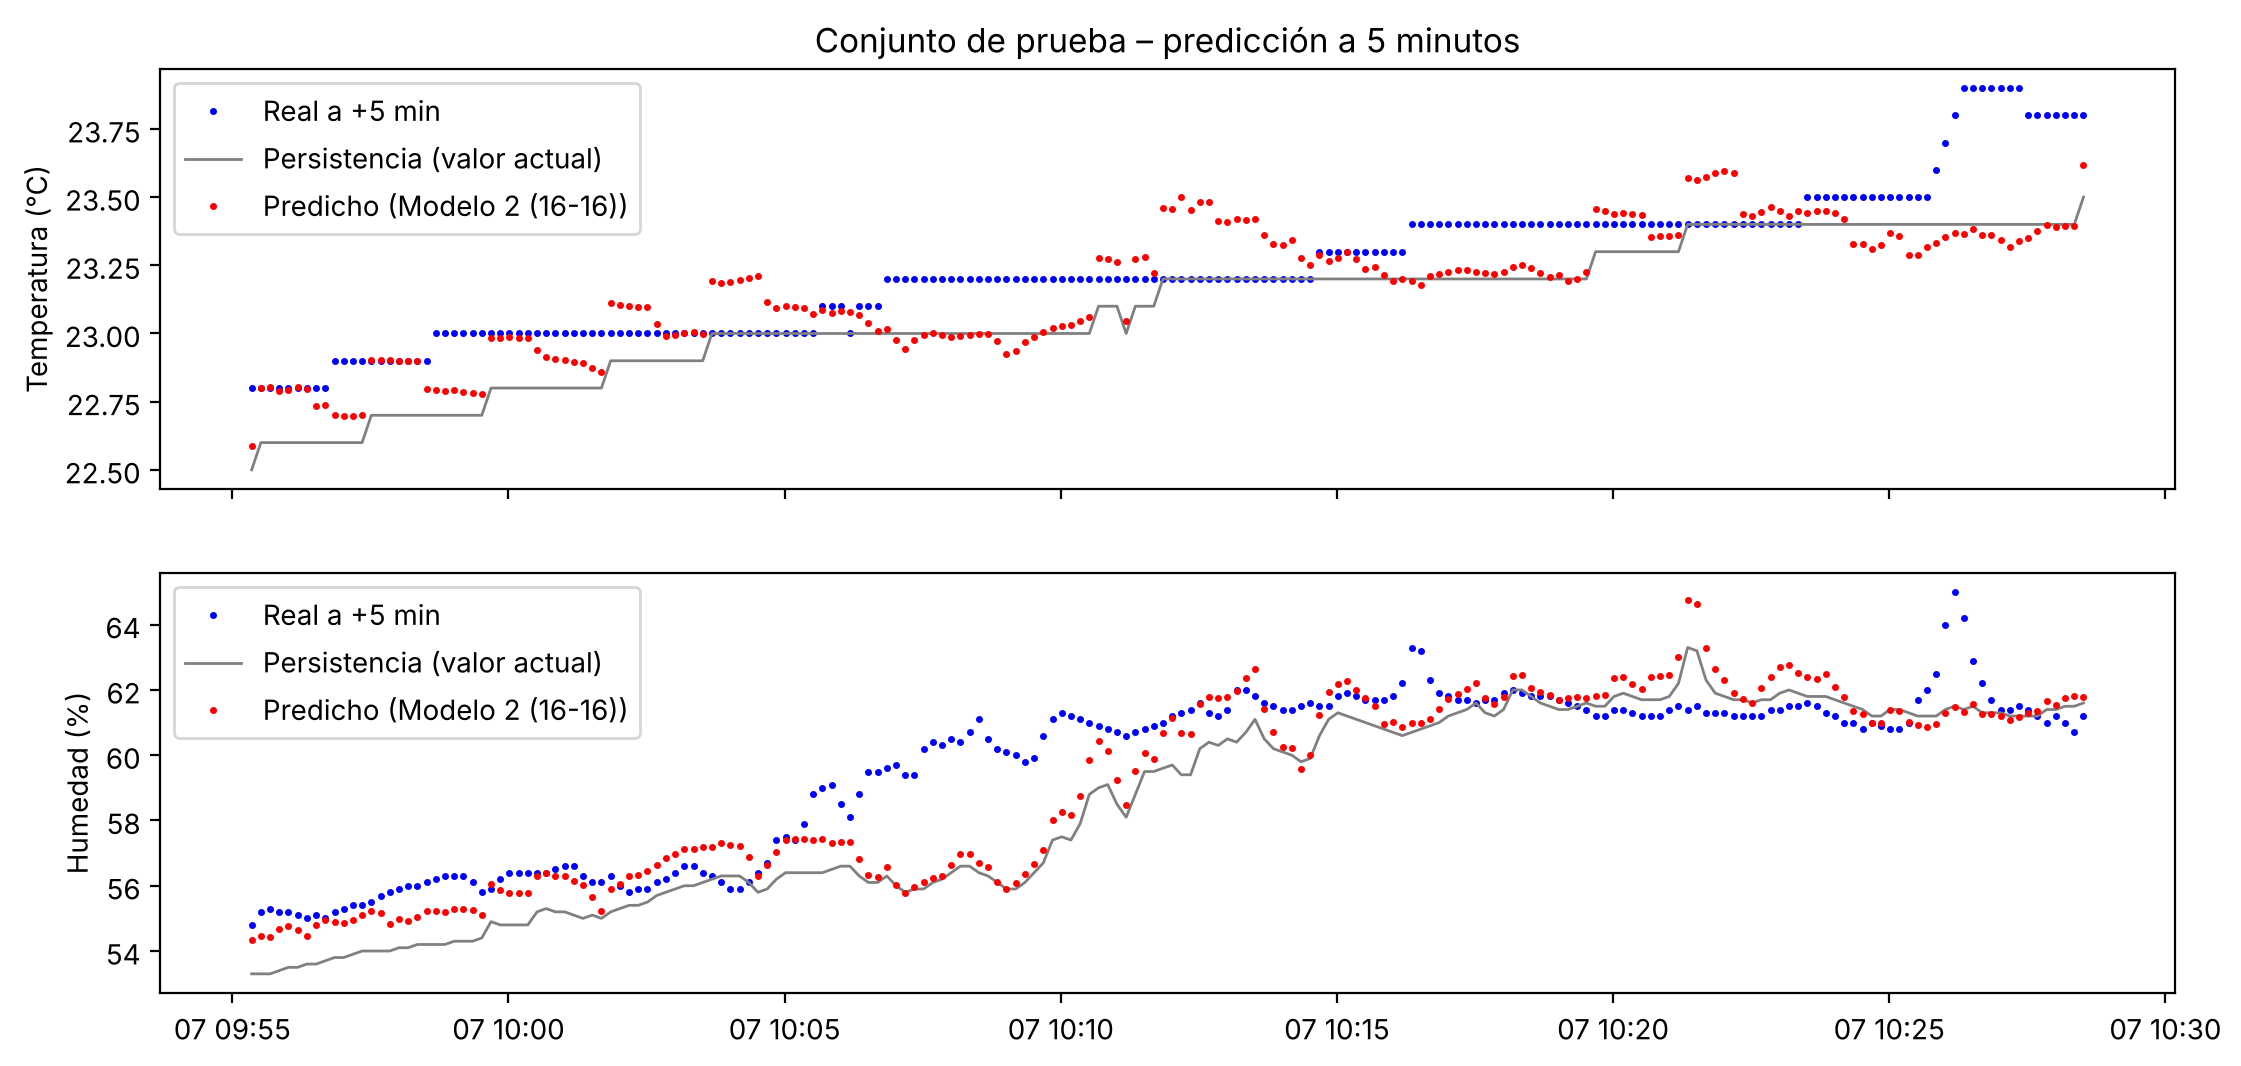

In [ ]:
# Valores absolutos predichos vs reales en la última sesión de prueba
ses_te = SES[idx_te]; s = ses_te.max(); m = ses_te == s
real_abs = ACT[idx_te][m] + y_test[m]
pred_abs = ACT[idx_te][m] + pred_final[m]
f = FECHA[idx_te][m] + np.timedelta64(5, "m")

fig, axs = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for k, (ax, nombre) in enumerate(zip(axs, ["Temperatura (°C)", "Humedad (%)"])):
    ax.plot(f, real_abs[:, k], "b.", ms=3, label="Real a +5 min")
    ax.plot(f, ACT[idx_te][m][:, k], color="gray", lw=1, label="Persistencia (valor actual)")
    ax.plot(f, pred_abs[:, k], "r.", ms=3, label=f"Predicho ({nombre_final})")
    ax.set_ylabel(nombre); ax.legend()
axs[0].set_title("Conjunto de prueba – predicción a 5 minutos")
plt.show()

### Alerta anticipada

Se aplica la regla de la bodega al valor **predicho** a 5 minutos y se compara con el estado **real** a 5 minutos.

In [ ]:
T_MIN, T_MAX, H_MIN, H_MAX = 15, 25, 50, 65
estado = lambda th: np.where((th[:, 0] >= T_MIN) & (th[:, 0] <= T_MAX) &
                             (th[:, 1] >= H_MIN) & (th[:, 1] <= H_MAX), "OK", "ALERTA")

act_te = ACT[idx_te]
est_real = estado(act_te + y_test)
for nombre, p in [("Persistencia", np.zeros_like(y_test)), (nombre_final, pred_final)]:
    print(f"{nombre:20s} acierto del estado a +5 min: {(estado(act_te + p) == est_real).mean():.1%}")

# Lo difícil es anticipar los CAMBIOS de estado (OK->ALERTA o ALERTA->OK en los próximos 5 min)
cambia = estado(act_te) != est_real
print(f"\nVentanas de prueba donde el estado cambia en 5 min: {cambia.sum()}")
for nombre, p in [("Persistencia", np.zeros_like(y_test)), (nombre_final, pred_final)]:
    print(f"{nombre:20s} anticipa correctamente el cambio: {(estado(act_te + p)[cambia] == est_real[cambia]).mean():.1%}")

Persistencia         acierto del estado a +5 min: 94.5%
Modelo 2 (16-16)     acierto del estado a +5 min: 98.0%

Ventanas de prueba donde el estado cambia en 5 min: 30
Persistencia         anticipa correctamente el cambio: 0.0%
Modelo 2 (16-16)     anticipa correctamente el cambio: 63.3%

Predicho +5 min  ALERTA   OK
Real +5 min                 
ALERTA              326   11
OK                    0  208


In [1]:
from sklearn.metrics import ConfusionMatrixDisplay

etiquetas = ["OK", "ALERTA"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    est_real, estado(act_te + pred_final),
    labels=etiquetas, cmap="Blues", colorbar=False, ax=ax
)
ax.set_xlabel("Predicho a +5 min")
ax.set_ylabel("Real a +5 min")
ax.set_title(f"Estado a +5 min – {nombre_final}")
plt.show()

NameError: name 'plt' is not defined

## 10. Conversión a TensorFlow Lite (cuantizado)

Igual que en clase: `TFLiteConverter` con `Optimize.DEFAULT`. Luego se comprueba que el modelo `.tflite` da los mismos resultados que el de Keras.

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(modelo_final)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quant_model = converter.convert()

with open("modelo_bodega.tflite", "wb") as f:
    f.write(tflite_quant_model)
print("Tamaño del modelo:", len(tflite_quant_model), "bytes")

INFO:tensorflow:Assets written to: /tmp/tmpp8v_bexq/assets


INFO:tensorflow:Assets written to: /tmp/tmpp8v_bexq/assets


Saved artifact at '/tmp/tmpp8v_bexq'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8), dtype=tf.float32, name='keras_tensor_2')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  139790435515856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139790435513360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139790434194576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139790434192464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139790434189776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139790435745040: TensorSpec(shape=(), dtype=tf.resource, name=None)


Tamaño del modelo: 3812 bytes


W0000 00:00:1794274120.403904   15202 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794274120.403935   15202 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794274120.404186   15202 reader.cc:83] Reading SavedModel from: /tmp/tmpp8v_bexq
I0000 00:00:1794274120.404457   15202 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794274120.404464   15202 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpp8v_bexq
I0000 00:00:1794274120.406703   15202 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1794274120.407225   15202 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794274120.425301   15202 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpp8v_bexq
I0000 00:00:1794274120.430031   15202 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 25852 microseconds.
I0000 00:00:1794274120.436976   15202

In [ ]:
# Verificar el modelo TFLite con el intérprete
interp = tf.lite.Interpreter(model_content=tflite_quant_model,
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

pred_tfl = []
for x in xn_test.astype(np.float32):
    interp.set_tensor(inp["index"], x[None, :]); interp.invoke()
    pred_tfl.append(interp.get_tensor(out["index"])[0])
pred_tfl = desnorm_y(np.array(pred_tfl))
print("MAE TFLite (T, H):", mae(pred_tfl, y_test).round(3), "| MAE Keras:", mae(pred_final, y_test).round(3))

# Operaciones que usa el modelo -> deben registrarse en el resolver del sketch de Arduino
ops = sorted({op["op_name"] for op in interp._get_ops_details()})
print("Operaciones del modelo:", ops)

MAE TFLite (T, H): [0.137 0.875] | MAE Keras: [0.137 0.875]
Operaciones del modelo: ['FULLY_CONNECTED']


/usr/local/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 11. Exportar el archivo `.h` para Arduino

Aquí se genera el `.h` con Python para incluir, además del modelo, las **constantes de normalización** y algunas **ventanas de prueba** reales; así el sketch no necesita copiar números a mano y, si se reentrena, basta con volver a subir el `.h`.

In [ ]:
def arr_c(v, fmt="{:.6f}f"):
    return "{" + ", ".join(fmt.format(float(a)) for a in np.ravel(v)) + "}"

# Ventanas de prueba para el modo demo del ESP32 (valores crudos, sin normalizar)
N_PUNTOS = len(LAGS_MIN) + 1          # t-4, t-3, t-2, t-1, t (minutos)
# 4 ventanas donde el estado cambia en los próximos 5 min + 4 repartidas en el conjunto de prueba
cambia_idx = idx_te[cambia]
demo_idx = np.concatenate([cambia_idx[np.linspace(0, len(cambia_idx) - 1, min(4, len(cambia_idx))).astype(int)],
                           idx_te[np.linspace(0, len(idx_te) - 1, 4).astype(int)]])
demo_T, demo_H, demo_rT, demo_rH = [], [], [], []
for i in demo_idx:
    a = ACT[i]
    # reconstruir los 5 puntos: valor actual + diferencias (en orden t-4min ... t)
    demo_T.append([a[0] + X[i][k] for k in [3, 2, 1, 0]] + [a[0]])
    demo_H.append([a[1] + X[i][4 + k] for k in [3, 2, 1, 0]] + [a[1]])
    demo_rT.append(a[0] + Y[i][0]); demo_rH.append(a[1] + Y[i][1])

lineas = [
    "// Generado automáticamente por el notebook TinyML_bodega_cafe.ipynb",
    f"// Modelo: {nombre_final} | entradas: {N_ENTRADAS} | salidas: {N_SALIDAS}",
    "#pragma once",
    "",
    f"#define N_ENTRADAS {N_ENTRADAS}",
    f"#define N_SALIDAS {N_SALIDAS}",
    f"#define N_PUNTOS {N_PUNTOS}          // puntos de la ventana: t-4min ... t",
    f"#define PASO_LAG {PASO_LAG}          // lecturas entre puntos (1 min)",
    f"#define HIST_LECTURAS {HIST + 1}     // lecturas que debe guardar el buffer",
    f"#define PERIODO_MS {PASO_S * 1000}   // periodo de muestreo usado en el entrenamiento",
    f"#define HORIZONTE_MIN {HORIZONTE * PASO_S // 60}",
    "",
    f"const float X_MEAN[N_ENTRADAS] = {arr_c(X_MEAN)};",
    f"const float X_STD[N_ENTRADAS]  = {arr_c(X_STD)};",
    f"const float Y_MEAN[N_SALIDAS]  = {arr_c(Y_MEAN)};",
    f"const float Y_STD[N_SALIDAS]   = {arr_c(Y_STD)};",
    "",
    f"#define DEMO_N {len(demo_idx)}",
    "const float DEMO_T[DEMO_N][N_PUNTOS] = {" + ", ".join(arr_c(r, "{:.1f}f") for r in demo_T) + "};",
    "const float DEMO_H[DEMO_N][N_PUNTOS] = {" + ", ".join(arr_c(r, "{:.1f}f") for r in demo_H) + "};",
    f"const float DEMO_REAL_T[DEMO_N] = {arr_c(demo_rT, '{:.1f}f')};",
    f"const float DEMO_REAL_H[DEMO_N] = {arr_c(demo_rH, '{:.1f}f')};",
    "",
    f"const unsigned int modelo_bodega_len = {len(tflite_quant_model)};",
    "alignas(16) const unsigned char modelo_bodega[] = {",
]
b = tflite_quant_model
for k in range(0, len(b), 12):
    lineas.append("  " + ", ".join(f"0x{x:02x}" for x in b[k:k+12]) + ",")
lineas.append("};")

with open("modelo_bodega.h", "w", encoding="utf-8") as f:
    f.write("\n".join(lineas) + "\n")
print("modelo_bodega.h generado")

modelo_bodega.h generado


In [ ]:
# Descargar los archivos (solo en Colab)
try:
    from google.colab import files
    files.download("modelo_bodega.h")
    files.download("modelo_bodega.tflite")
except ImportError:
    pass

## 12. Conclusiones

* Con estos datos, predecir una variable a partir de la otra o a partir de la hora no es viable (correlación baja y pocas horas cubiertas). El problema que sí tiene información es el **pronóstico a corto plazo**.
* El resultado se compara siempre contra la persistencia. La mejora está sobre todo en la **humedad**, que es la variable que más se mueve en la bodega; en temperatura la mejora es pequeña porque casi no cambia en 5 minutos.
* El modelo lineal y la red 16-16 quedan prácticamente iguales en prueba: con ~8 horas de datos la red casi no encuentra relaciones no lineales que aprovechar. El criterio de exportación es el error de validación, prefiriendo el lineal si la red no lo mejora al menos un 2 %.
* La utilidad real está en los **cambios de estado**: la persistencia nunca anticipa un cambio (0 %), mientras que el modelo anticipa una parte importante de ellos 5 minutos antes.
* **Limitaciones:** solo 4 sesiones y ~2.900 lecturas; el modelo no ha visto días completos, lluvia, noche, etc. Con más días de recolección se podría alargar el horizonte (p. ej. 10 o 15 minutos) y reentrenar sin cambiar el sketch.